# 🏀 NBA Draft Analytics — État du projet

**Objectif :** construire une base SQLite qui relie les prospects de la draft NBA (mesures du Draft Combine, tirs, profil)
à leur carrière en NBA, pour pouvoir ensuite **prédire la réussite d'un joueur draftable**.

Ce notebook présente :
1. l'architecture du code,
2. ce que contient la base aujourd'hui,
3. l'avancement du pipeline,
4. quelques premières explorations des données,
5. les prochaines étapes.

## 1. Architecture du code

| Fichier | Rôle |
|---|---|
| `config.py` | Paramètres : saisons, délais API, proxy, mesures de tracking |
| `database.py` | Schéma SQLite (25 tables), `upsert_df`, checkpoints de reprise |
| `utils.py` | Logs, barres de progression, décorateur `@api_call` (rate-limit + retry) |
| `fetch_draft.py` | Draft Combine (anthropométrie, athlétisme, tir) + historique de draft |
| `fetch_teams.py` | Équipes, effectifs, coachs, stats d'équipe, splits |
| `fetch_players.py` | Liste des joueurs, infos, stats saison (classiques, avancées, scoring, hustle, tracking), carrière |
| `fetch_shots.py` | Chaque tir (position, zone, réussi/raté) des joueurs draftés |
| `fetch_college.py` | Stats NCAA, date de naissance et force des équipes (Barttorvik, 2008-2026) ; lien avec la draft |
| `fetch_ages.py` | Date de naissance de tous les draftés : Barttorvik, sinon Wikidata (une requête SPARQL) |
| `fetch_bbref.py` | BPM / VORP / WS par saison NBA (Basketball-Reference), reliés aux identifiants NBA |
| `modeling.py` | Table de modélisation + modèles prédictifs |
| `import_kaggle.py` | Import hors-ligne depuis le dataset Kaggle si stats.nba.com bloque |
| `graph_builder.py` | Graphe joueurs ↔ équipes ↔ coachs (NetworkX, export Gephi `.gexf`) |
| `main.py` | CLI : `python main.py --step <étape>` — 16 étapes, reprise automatique |

```
setup → draft_combine → draft_history → teams → player_list → season_stats → player_info
      → hustle → tracking → career → shots_draft → shots_combine → graph
      → college → ages → bbref      (hors API NBA)          puis : model
```

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Arc

DB = "nba_draft_analytics.db"
conn = sqlite3.connect(f"file:{DB}?mode=ro", uri=True)   # lecture seule
q = lambda sql, **kw: pd.read_sql_query(sql, conn, **kw)

# Style commun
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY, INK, MUTED = "#c9c8c3", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#eeeeec", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
})

## 2. Contenu de la base

Taille du fichier : 264 Mo  —  27 tables  —  1,084,637 lignes


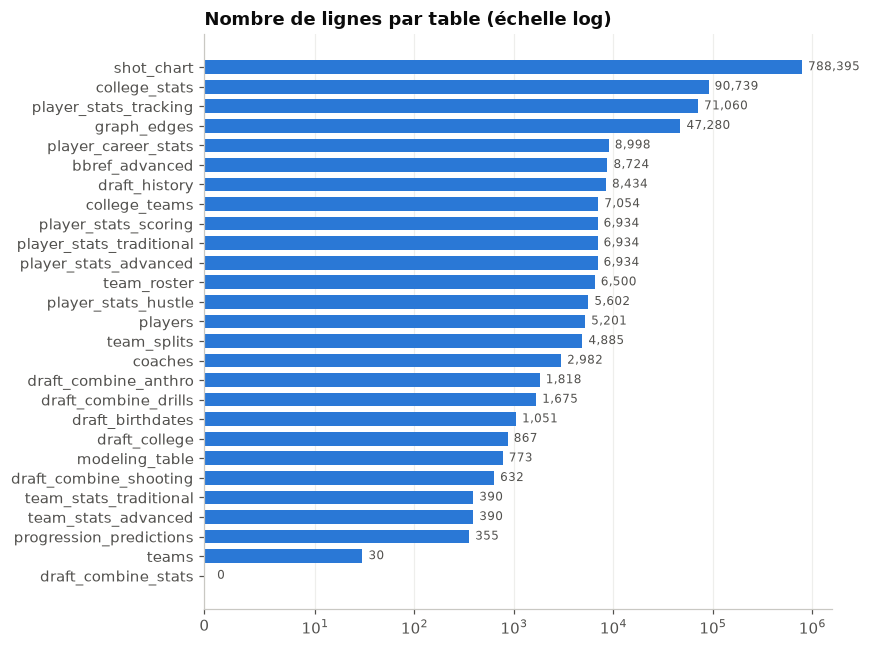

In [2]:
tables = q("SELECT name FROM sqlite_master WHERE type='table' "
           "AND name NOT LIKE 'sqlite_%' AND name != '_checkpoints'")["name"]
counts = pd.Series({t: q(f'SELECT COUNT(*) n FROM "{t}"')["n"][0] for t in tables}).sort_values()

import os
print(f"Taille du fichier : {os.path.getsize(DB) / 1e6:.0f} Mo  —  {len(counts)} tables  —  {counts.sum():,} lignes")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(counts.index, counts.values, color=[GRAY if v == 0 else BLUE for v in counts.values], height=0.7)
ax.set_xscale("symlog", linthresh=10)
ax.set_title("Nombre de lignes par table (échelle log)")
for i, v in enumerate(counts.values):
    ax.text(max(v, 1) * 1.15, i, f"{v:,}", va="center", fontsize=8, color=MUTED)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Lecture :** le gros volume vient des tirs (`shot_chart`, ~790 k tirs) et du tracking.
`draft_combine_stats` est vide **volontairement** (l'endpoint ne renvoie pas les stats universitaires) : elles viennent maintenant de Barttorvik (`college_stats`).

### Couverture par saison

In [3]:
season_tables = {
    "team_roster": "season", "team_stats_traditional": "season",
    "player_stats_traditional": "season", "player_stats_tracking": "season",
    "shot_chart": "season", "draft_combine_anthro": "season",
}
cov = pd.concat({t: q(f"SELECT {c} AS season, COUNT(*) n FROM {t} GROUP BY 1").set_index("season")["n"]
                 for t, c in season_tables.items()}, axis=1)
cov = cov.loc[cov.index >= "2014-15"].fillna(0).astype(int).T
cov

season,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
team_roster,450,451,451,502,497,510,503,506,508,532,534,530,526
team_stats_traditional,30,30,30,30,30,30,30,30,30,30,30,30,30
player_stats_traditional,492,476,486,540,530,529,540,605,539,572,569,582,474
player_stats_tracking,5412,5236,5346,5940,5830,5819,5940,6655,5929,6292,6259,6402,0
shot_chart,0,0,0,0,0,0,0,135221,151494,158880,168152,174648,0
draft_combine_anthro,56,58,56,63,69,70,45,65,61,67,83,79,78


- **Équipes / effectifs / coachs :** 2014-15 → 2025-26 (12 saisons) ✅
- **Stats joueurs (classiques, avancées, scoring, hustle, tracking) :** 2014-15 → 2025-26 ✅
  (hustle à partir de 2015-16 : la NBA ne le publie pas avant)
- **Saison 2026-27 (en cours) :** stats classiques / avancées / scoring seulement (~18 matchs au 23 nov.) ;
  le modèle ne l'utilise pas (`LAST_COMPLETE_SEASON = "2025-26"` dans `config.py`)
- **Tirs :** 2021-22 → 2025-26 seulement (les tirs 2014-2021 ne sont pas nécessaires pour le modèle)
- **Draft Combine :** 2000 → 2026 ✅ ; **historique de draft :** 1947 → 2026 ✅
- **NCAA (Barttorvik) :** saisons 2007-08 → 2025-26, ~91 k lignes joueur×saison + force de chaque équipe (`college_teams`) ✅
  → `draft_college` relie 99 % des draftés universitaires depuis 2009 à leur fiche NCAA
- **Date de naissance des draftés (`draft_birthdates`) :** 98 % des draftés depuis 2009 — Barttorvik pour les
  universitaires, Wikidata pour les autres (les deux sources concordent à 99,6 % là où elles se recoupent) ✅
- **BPM / VORP (Basketball-Reference) :** 2014-15 → 2025-26, > 99 % des joueurs reliés à leur identifiant NBA ✅

## 3. Avancement du pipeline

In [4]:
ck = q("SELECT task, status, updated_at FROM _checkpoints")
ck["étape"] = ck["task"].str.split(":").str[0]
progress = ck.pivot_table(index="étape", columns="status", values="task", aggfunc="count", fill_value=0)
progress["dernière maj"] = ck.groupby("étape")["updated_at"].max()
progress.sort_values("dernière maj")

status,done,failed,dernière maj
étape,,,
teams_static,1,0,2026-11-02 21:05:43
tracking,132,0,2026-11-16 10:04:12
hustle,11,1,2026-11-16 10:13:01
player_info,1633,18,2026-11-16 10:49:45
college,19,0,2026-11-23 18:16:17
career,1028,8,2026-11-23 18:27:56
shots,1764,7,2026-11-23 18:28:31
draft_history,7,0,2026-11-23 20:00:33
draft_combine,27,0,2026-11-23 20:00:45


In [5]:
steps = ["setup", "draft_combine", "draft_history", "teams", "player_list", "season_stats",
         "player_info", "hustle", "tracking", "career", "shots_draft", "shots_combine", "graph",
         "college", "ages", "bbref", "model"]
status = {s: "fait" for s in steps}
status.update(college="fait (23/11)", ages="fait (23/11)", bbref="fait (23/11)", model="fait (23/11)")
pd.DataFrame({"étape": steps, "statut": [status[s] for s in steps]}).set_index("étape")

,statut
étape,
setup,fait
draft_combine,fait
draft_history,fait
teams,fait
player_list,fait
season_stats,fait
player_info,fait
hustle,fait
tracking,fait


**Bilan (23 nov.) : toutes les étapes sont terminées**, y compris les tirs et les deux nouvelles étapes hors API NBA
(`college`, `ages`, `bbref`). La draft 2026 (60 choix, Combine 2026) est intégrée. Grâce aux checkpoints, une interruption n'est jamais grave : relancer la même commande reprend
là où on s'était arrêté.

Échecs restants (colonne `failed`), tous vérifiés et sans conséquence :
- `shots` (7) : joueurs ayant joué 1 à 4 matchs sans tenter un seul tir — il n'y a rien à télécharger ;
- `career` (8) et `player_info` (18) : l'API renvoie `KeyError: 'resultSet'` (pas de données pour ces joueurs, même après relance) ;
- `hustle:2014-15` : la NBA ne publie le hustle qu'à partir de 2015-16.

## 4. Explorations

### 4.1 La draft : d'où viennent les joueurs ?

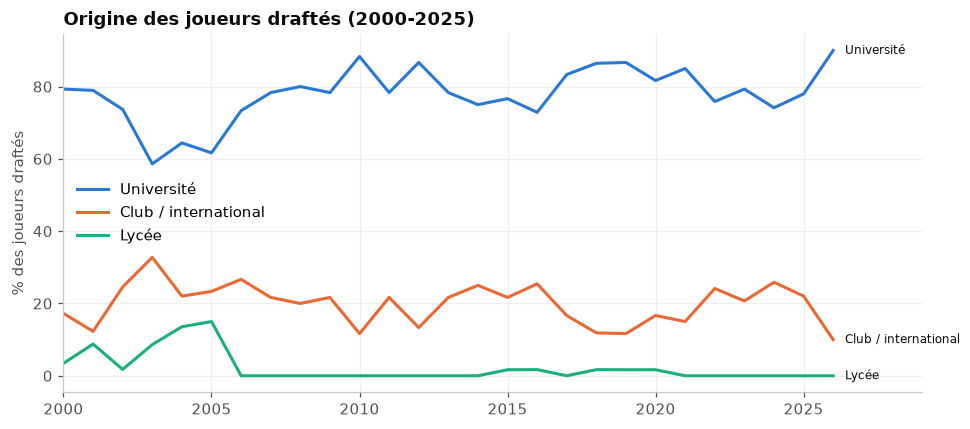

In [6]:
d = q("SELECT CAST(season AS INT) AS annee, organization_type FROM draft_history "
      "WHERE CAST(season AS INT) >= 2000 AND organization_type != ''")
d["origine"] = d["organization_type"].replace({"College/University": "Université",
                                               "Other Team/Club": "Club / international",
                                               "High School": "Lycée"})
share = pd.crosstab(d["annee"], d["origine"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(9, 4))
for col, color in [("Université", BLUE), ("Club / international", ORANGE), ("Lycée", AQUA)]:
    ax.plot(share.index, share[col], color=color, lw=2, label=col)
    ax.text(share.index[-1] + 0.4, share[col].iloc[-1], col, color=INK, fontsize=8, va="center")
ax.set_ylabel("% des joueurs draftés"); ax.set_xlim(2000, 2029)
ax.set_title("Origine des joueurs draftés (2000-2025)")
ax.legend(frameon=False, loc="center left")
plt.tight_layout(); plt.show()

Les lycéens disparaissent après 2005 (règle *one-and-done*) ; la part internationale oscille entre ~12 et ~33 % (environ 1 drafté sur 5).

### 4.2 Draft Combine : envergure vs taille

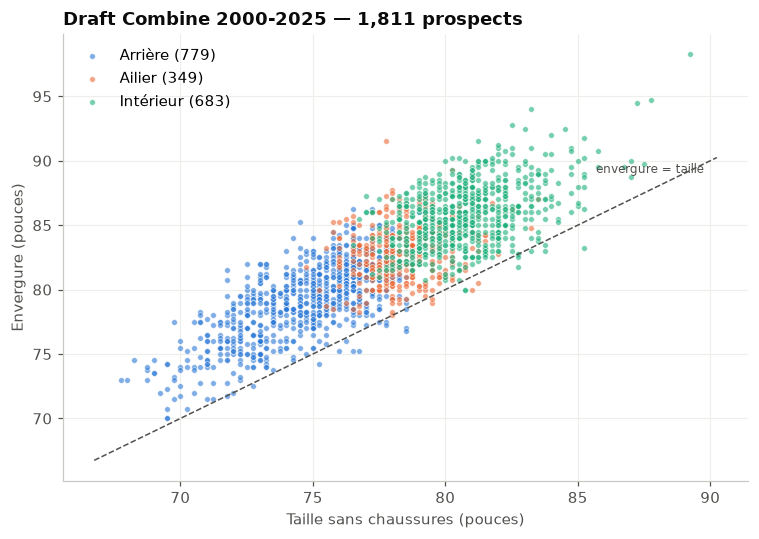

Envergure - taille : moyenne +4.7 pouces


In [7]:
a = q("SELECT player_name, position, height_wo_shoes AS taille, wingspan AS envergure "
      "FROM draft_combine_anthro WHERE height_wo_shoes > 0 AND wingspan > 0")
def poste(p):
    p = (p or "").split("-")[0]
    return {"PG": "Arrière", "SG": "Arrière", "SF": "Ailier"}.get(p, "Intérieur" if p in ("PF", "C") else None)
a["poste"] = a["position"].map(poste)
a = a.dropna(subset=["poste"])

fig, ax = plt.subplots(figsize=(7, 5))
for p, color in [("Arrière", BLUE), ("Ailier", ORANGE), ("Intérieur", AQUA)]:
    s = a[a["poste"] == p]
    ax.scatter(s["taille"], s["envergure"], s=14, color=color, alpha=0.6,
               edgecolor="white", linewidth=0.5, label=f"{p} ({len(s)})")
lims = [a["taille"].min() - 1, a["taille"].max() + 1]
ax.plot(lims, lims, color=MUTED, lw=1, ls="--")
ax.text(lims[1] - 0.5, lims[1] - 1.2, "envergure = taille", color=MUTED, fontsize=8, ha="right")
ax.set_xlabel("Taille sans chaussures (pouces)"); ax.set_ylabel("Envergure (pouces)")
ax.set_title(f"Draft Combine 2000-2025 — {len(a):,} prospects")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

print(f"Envergure - taille : moyenne {(a.envergure - a.taille).mean():+.1f} pouces")

### 4.3 Rang de draft et carrière NBA

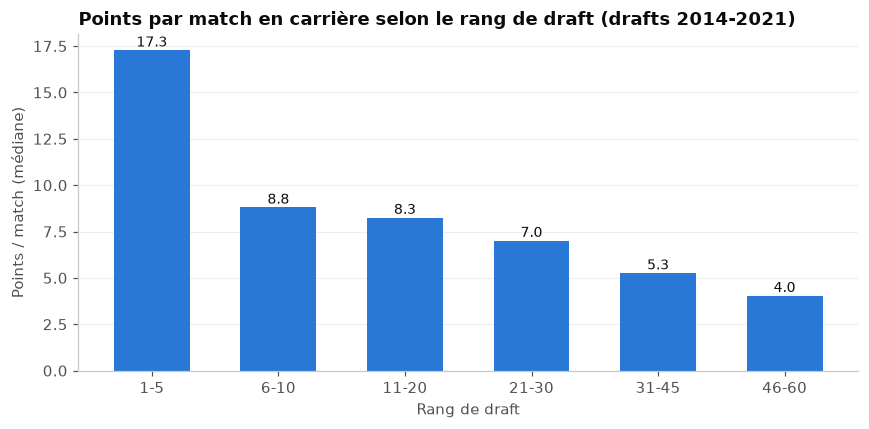

,joueurs,matchs,pts_match
1-5,40,382.0,17.3
6-10,40,386.5,8.8
11-20,80,356.5,8.3
21-30,79,279.0,7.0
31-45,108,149.5,5.3
46-60,85,54.0,4.0


In [8]:
career = q('''
    SELECT h.overall_pick AS pick, c.player_id, SUM(c.gp) AS matchs, SUM(c.pts) AS pts
    FROM player_career_stats c
    JOIN draft_history h ON h.player_id = c.player_id
    WHERE c.team_id != 0 AND CAST(h.season AS INT) BETWEEN 2014 AND 2021
    GROUP BY c.player_id
''')
career["pts_par_match"] = career["pts"] / career["matchs"].clip(lower=1)
by_pick = career.groupby(pd.cut(career["pick"], [0, 5, 10, 20, 30, 45, 60]), observed=True) \
                .agg(joueurs=("player_id", "count"), matchs=("matchs", "median"), pts_match=("pts_par_match", "median"))
by_pick.index = [f"{int(i.left)+1}-{int(i.right)}" for i in by_pick.index]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_pick.index, by_pick["pts_match"], color=BLUE, width=0.6)
for i, v in enumerate(by_pick["pts_match"]):
    ax.text(i, v + 0.2, f"{v:.1f}", ha="center", fontsize=9, color=INK)
ax.set_xlabel("Rang de draft"); ax.set_ylabel("Points / match (médiane)")
ax.set_title("Points par match en carrière selon le rang de draft (drafts 2014-2021)")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
by_pick.round(1)

Les carrières couvrent maintenant tous les draftés 2014-2021 ayant joué en NBA. ⚠️ Ce graphique ne compte que
les joueurs **ayant joué au moins un match** : les draftés jamais apparus en NBA (fréquents au 2ᵉ tour) n'y figurent
pas — le modèle de la section 5, lui, les compte avec 0 minute.

### 4.4 Shot chart d'un joueur

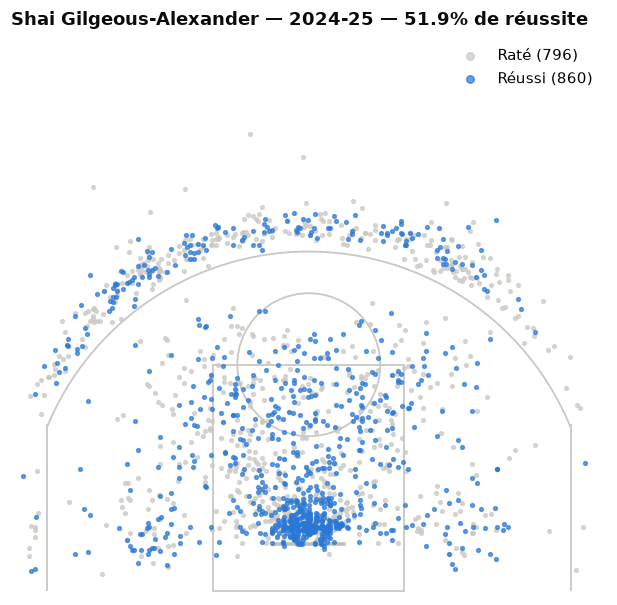

In [9]:
def draw_court(ax, color=GRAY):
    for patch in [Circle((0, 0), 7.5, fill=False), Rectangle((-30, -7.5), 60, -1),
                  Rectangle((-80, -47.5), 160, 190, fill=False), Circle((0, 142.5), 60, fill=False),
                  Rectangle((-220, -47.5), 0, 140), Rectangle((220, -47.5), 0, 140),
                  Arc((0, 0), 475, 475, theta1=22, theta2=158)]:
        patch.set(edgecolor=color, lw=1.2); ax.add_patch(patch)
    ax.set_xlim(-250, 250); ax.set_ylim(-50, 420); ax.set_aspect("equal"); ax.axis("off")

PLAYER, SEASON = "Shai Gilgeous-Alexander", "2024-25"
s = q("SELECT loc_x, loc_y, shot_made_flag FROM shot_chart WHERE player_name = ? AND season = ?",
      params=(PLAYER, SEASON))

fig, ax = plt.subplots(figsize=(6, 5.6))
draw_court(ax)
for flag, color, label in [(0, GRAY, "Raté"), (1, BLUE, "Réussi")]:
    t = s[s["shot_made_flag"] == flag]
    ax.scatter(t["loc_x"], t["loc_y"], s=6, color=color, alpha=0.7, label=f"{label} ({len(t):,})")
ax.set_title(f"{PLAYER} — {SEASON} — {s.shot_made_flag.mean():.1%} de réussite")
ax.legend(frameon=False, loc="upper right", markerscale=2)
plt.tight_layout(); plt.show()

### 4.5 Le graphe de relations

In [10]:
q('''SELECT edge_type, COUNT(*) AS aretes, COUNT(DISTINCT source_id) AS sources
     FROM graph_edges GROUP BY 1''')

,edge_type,aretes,sources
0,coaches,2685,613
1,drafted_by,3634,3582
2,plays_for,5974,1486
3,teammate,34987,1378


Le graphe (`nba_graph.gexf`, ouvrable dans Gephi) relie joueurs, équipes et coachs sur 2014-2026 :
`plays_for` (joueur → équipe par saison), `coaches`, `drafted_by` et `teammate` (poids = nombre de saisons ensemble).

## 5. Premier modèle prédictif

**Question :** à partir de ce qu'on sait le soir de la draft, peut-on prédire si un joueur deviendra
un **joueur de rotation** ?

- **Population :** les joueurs draftés de 2014 à 2021.
- **Cible `etabli`** : ≥ 4 000 minutes jouées sur ses **4 premières saisons NBA** (≈ 1 000 min/saison),
  comptées à partir de ses **débuts en NBA** — un joueur resté en Europe après sa draft (Jokic, Bogdanovic, Saric)
  n'est pas pénalisé. Un drafté qui n'a jamais joué compte 0 minute.
- **Variables — uniquement ce qu'on sait le soir de la draft :** rang de draft, origine,
  présence au Draft Combine et ses mesures (taille, poids, poste, envergure, détente, agilité, vitesse…),
  **âge à la draft** et **stats NCAA** (dernière saison : BPM, points, rebonds, passes, TS%, usage, % à 3 pts…,
  plus nombre de saisons, LF en carrière, conférence majeure, rang de recrutement, force de l'équipe) — source Barttorvik.

> ⚠️ **Fuite évitée :** l'âge, la taille et le poste « officiels NBA » viennent de `CommonPlayerInfo`, qui n'existe
> que pour les joueurs ayant joué en NBA. Les utiliser revenait à dire au modèle « valeur manquante = n'a jamais joué »
> (le R² montait artificiellement à 0,76). Ils sont donc exclus. L'âge vient désormais de **Barttorvik** (universitaires) et de **Wikidata** (internationaux, G League…),
> deux sources qui ne dépendent pas d'avoir joué en NBA. Il est connu pour 98 % des draftés ; les 2 % restants
> (un peu plus fréquents chez les internationaux jamais venus en NBA) reçoivent la médiane de leur origine,
> sans indicateur « âge manquant » qui pourrait trahir l'issue.
- Le rang entre sous deux formes, `pick` et `log(pick)` : le log décrit bien le haut de la draft, le brut la fin.
- Le code est dans `modeling.py` (`python main.py --step model`) : il écrit la table `modeling_table` dans la base.

In [11]:
from IPython.display import display
from modeling import build_modeling_table, evaluate, predict_recent

table = build_modeling_table(include_unlabeled=True)
labeled = table.dropna(subset=["etabli"])
print(f"{len(labeled)} joueurs avec un résultat connu — {labeled['etabli'].mean():.0%} sont devenus joueurs de rotation")
labeled.groupby("draft_year").agg(draftes=("player_id", "size"), etablis=("etabli", "mean"),
                                  ont_fait_le_combine=("a_fait_combine", "mean")).round(2)

471 joueurs avec un résultat connu — 38% sont devenus joueurs de rotation


,draftes,etablis,ont_fait_le_combine
draft_year,,,
2014,59,0.39,0.73
2015,60,0.40,0.62
2016,58,0.22,0.64
2017,59,0.39,0.69
2018,60,0.47,0.75
2019,58,0.40,0.74
2020,59,0.39,0.44
2021,58,0.38,0.67


In [12]:
res = evaluate(table)   # validation croisée 5 plis × 5 répétitions
res["scores"].round(3)

c:\Users\Trist\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Trist\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Trist\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Trist\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Trist\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(e

,AUC,AUC écart-type,Brier
modèle,,,
Rang de draft seul (logistique),0.833,0.035,0.159
Rang + âge + NCAA (logistique),0.820,0.035,0.165
Toutes variables (logistique),0.825,0.032,0.166
Toutes variables (gradient boosting),0.800,0.043,0.176


**AUC** = probabilité que le modèle classe un joueur établi au-dessus d'un joueur qui ne l'est pas
(0,5 = hasard, 1 = parfait). La comparaison clé : **le Combine, l'âge et les stats NCAA apportent-ils quelque chose
au-delà du rang de draft**, qui résume déjà l'avis de 30 équipes de scouts ?

**Résultat (23 nov.) : non, pour savoir qui deviendra joueur de rotation.** Le rang de draft seul atteint une AUC
d'environ 0,83 ; ajouter l'origine, le Combine, l'âge et les stats NCAA ne l'améliore pas (l'écart est inférieur à
l'écart-type). Ces informations sont déjà « intégrées » dans le choix des équipes — mais voir plus bas la cible *qualité*.

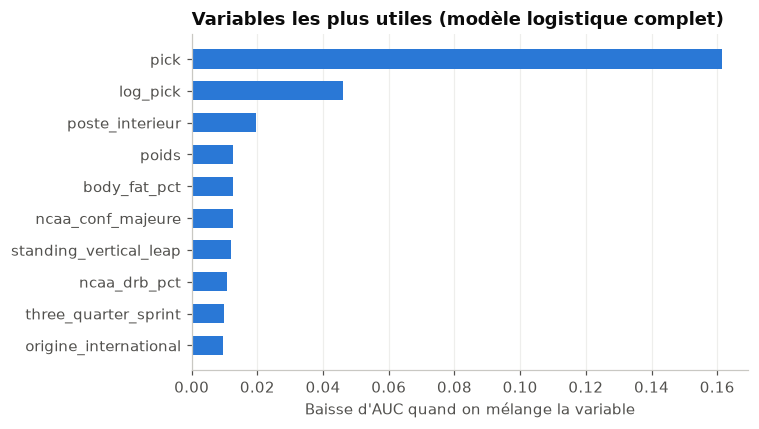

In [13]:
imp = res["importance"].head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.set_xlabel("Baisse d'AUC quand on mélange la variable")
ax.set_title("Variables les plus utiles (modèle logistique complet)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

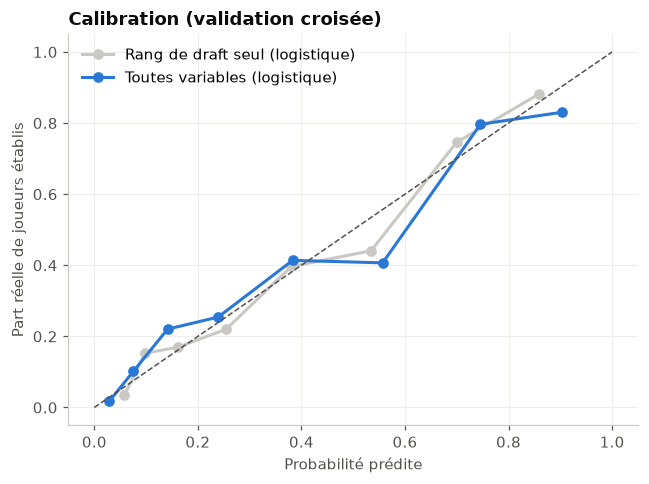

In [14]:
# Calibration : probabilité prédite (hors échantillon) vs taux réel
oof = res["oof"]
fig, ax = plt.subplots(figsize=(6, 4.5))
for name, color in [("Rang de draft seul (logistique)", GRAY), ("Toutes variables (logistique)", BLUE)]:
    b = oof.groupby(pd.qcut(oof[name], 8, duplicates="drop"), observed=True).agg(p=(name, "mean"), y=("etabli", "mean"))
    ax.plot(b["p"], b["y"], marker="o", ms=6, lw=2, color=color, label=name)
ax.plot([0, 1], [0, 1], ls="--", lw=1, color=MUTED)
ax.set_xlabel("Probabilité prédite"); ax.set_ylabel("Part réelle de joueurs établis")
ax.set_title("Calibration (validation croisée)")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### Validation dans le temps

La validation croisée mélange les années. Plus réaliste : **entraîner sur les drafts 2014-2019 et prédire
2020-2021**, comme si on était en 2020.

In [15]:
from modeling import evaluate_temporal
tmp = evaluate_temporal(table, train_until=2019)
print(f"Entraînement : {tmp.attrs['n_train']} joueurs — test : drafts {tmp.attrs['test_years']} ({tmp.attrs['n_test']} joueurs)")
tmp.round(3)

Entraînement : 354 joueurs — test : drafts 2020-2021 (117 joueurs)


,AUC test,Brier test
modèle,,
Rang de draft seul (logistique),0.849,0.151
Rang + âge + NCAA (logistique),0.848,0.152
Toutes variables (logistique),0.839,0.163
Toutes variables (gradient boosting),0.785,0.195


Même conclusion : sur des drafts jamais vues, **le rang de draft seul fait aussi bien** que les modèles plus riches
(le modèle « rang + âge + NCAA » est à égalité ; le gradient boosting perd : il sur-apprend sur ~350 joueurs).

### Cible continue : combien de minutes ?

Au lieu de oui/non, on prédit `log(1 + minutes)` sur les 4 premières saisons.
**Spearman** mesure si le modèle *classe* bien les joueurs ; le **R²** mesure la précision des valeurs.

In [16]:
from modeling import evaluate_regression
evaluate_regression(table).round(3)

,R²,Spearman,Spearman écart-type
modèle,,,
Rang de draft seul (linéaire),0.353,0.657,0.045
Rang + âge + NCAA (linéaire),0.391,0.642,0.060
Toutes variables (linéaire),0.368,0.631,0.064
Toutes variables (gradient boosting),0.401,0.652,0.048


Le rang seul (brut + log) explique déjà ~35 % de la variance ; les autres variables ajoutent quelques points de R²
mais le **Spearman ne bouge pas** (~0,65) : le classement des joueurs n'est pas meilleur. Le petit gain de R² vient
surtout de la **présence au Combine** (18 % des absents ne jouent jamais un match NBA, contre 4 % des présents).

> Correction par rapport au 16 nov. : le gain de R² attribué alors à « toutes les variables » (0,23 → 0,38) venait
> surtout de la forme du rang (le modèle de référence n'utilisait que `log(pick)`). Avec `pick` + `log(pick)`,
> la référence passe à 0,35.

### L'âge à la draft

Les joueurs jeunes réussissent beaucoup plus souvent… mais ils sont aussi draftés plus haut. Une fois le rang connu,
l'âge apporte-t-il encore quelque chose ?

In [17]:
import numpy as np
import statsmodels.formula.api as smf

lab = labeled[labeled["source_age"].notna()]           # vraies dates de naissance seulement
display(lab["source_age"].value_counts().rename("joueurs"))
by_age = lab.groupby(lab["age_draft"].round().clip(19, 24))["etabli"].agg(["mean", "size"])
by_age.columns = ["taux d'établis", "joueurs"]
display(by_age.round(2))

for nom, sous in [("tous les draftés", lab), ("hors universitaires", lab[lab["organization_type"] != "College/University"])]:
    fit = smf.logit("etabli ~ pick + log_pick + age_draft", sous).fit(disp=0)
    print(f"{nom} ({len(sous)}) : coefficient de l'âge {fit.params['age_draft']:+.3f}, p = {fit.pvalues['age_draft']:.2f}")

ImportError: cannot import name '_lazywhere' from 'scipy._lib._util' (c:\Users\Trist\anaconda3\Lib\site-packages\scipy\_lib\_util.py)

**Non.** Brut, l'écart est énorme (≈ 52 % d'établis à 19 ans contre ≈ 15 % à 24 ans), mais **à rang de draft égal,
l'âge n'a pas d'effet significatif** (p ≈ 0,3), y compris chez les internationaux (p ≈ 0,7), dont l'âge vient de Wikidata.
Les équipes valorisent déjà correctement la jeunesse : l'âge est « dans » le rang.

### Cible qualité : BPM, VORP, PIE

Être « établi » mesure surtout le **temps de jeu** — que les équipes donnent volontiers à leurs choix hauts.
On mesure maintenant la **qualité** sur la même fenêtre de 4 saisons :

- **VORP** cumulé (Basketball-Reference) : qualité × temps de jeu, 0 pour un joueur qui n'a jamais joué ;
- **BPM** et **PIE** pondérés par les minutes, pour les joueurs ayant joué au moins 1 000 minutes (qualité seule) ;
- **valeur vs rang** = VORP − VORP attendu à ce rang de draft (courbe décroissante ajustée sur tous les draftés) :
  > 0 = meilleur que sa position de draft. C'est la cible « battre les scouts ».

modèle,Rang de draft seul (linéaire),Rang + âge + NCAA (linéaire),Toutes variables (linéaire),Toutes variables (gradient boosting)
minutes (n=471),0.657,0.642,0.631,0.652
vorp (n=471),0.185,0.298,0.284,0.286
bpm (n=317),0.065,0.365,0.319,0.357
pie (n=317),0.122,0.429,0.388,0.418
valeur_vs_rang (n=471),-0.038,0.221,0.199,0.152


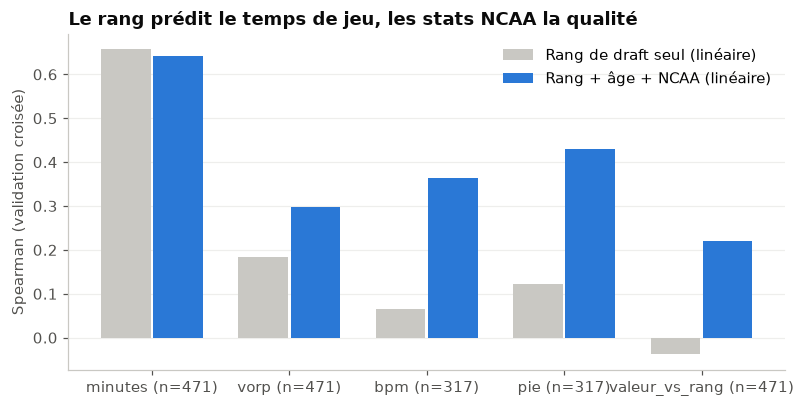

In [18]:
from modeling import TARGETS

rows = {}
for target in ["minutes", "vorp", "bpm", "pie", "valeur_vs_rang"]:
    r = evaluate_regression(table, target)
    rows[f"{target} (n={r.attrs['n']})"] = r["Spearman"]
quality = pd.DataFrame(rows).T
display(quality.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
models = ["Rang de draft seul (linéaire)", "Rang + âge + NCAA (linéaire)"]
x = np.arange(len(quality))
for k, (m, color) in enumerate(zip(models, [GRAY, BLUE])):
    ax.bar(x + (k - 0.5) * 0.38, quality[m], width=0.36, color=color, label=m)
ax.set_xticks(x, quality.index)
ax.set_ylabel("Spearman (validation croisée)")
ax.set_title("Le rang prédit le temps de jeu, les stats NCAA la qualité")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**C'est le résultat le plus intéressant du projet.**

- Le rang de draft prédit très bien le **temps de jeu** (Spearman ≈ 0,66) mais presque pas la **qualité** :
  parmi les joueurs qui ont joué, Spearman ≈ 0,07 pour le BPM et ≈ 0,12 pour le PIE.
- Les **stats NCAA** font beaucoup mieux sur la qualité : Spearman ≈ 0,37 (BPM) et ≈ 0,43 (PIE).
- Sur la **valeur vs rang**, le rang seul ne fait par construction rien (≈ 0), le modèle NCAA atteint ≈ 0,22 :
  il repère un peu mieux que le hasard les joueurs qui dépasseront leur rang — mais son R² est négatif,
  il ne sait pas *de combien*.
- Interprétation : un choix haut reçoit des minutes quoi qu'il arrive (investissement de l'équipe, reconstruction),
  alors que la production universitaire dit davantage sur **ce que le joueur fera de ces minutes**.
- Deux pistes testées sans gain : un modèle qualité **compact** (17 variables) fait *moins bien* que le jeu NCAA
  complet (la régularisation Ridge suffit contre le sur-apprentissage), et la **force de l'équipe universitaire**
  (Barthag, SOS) n'ajoute que +0,005 de Spearman.
- Limite : les stats NCAA manquent pour les internationaux (~20 % des draftés), imputés par la médiane ;
  et 317 joueurs seulement ont ≥ 1 000 minutes, d'où des écarts-types de ±0,07-0,10.

### Valeur du choix : les bonnes affaires et les déceptions (drafts 2014-2021)

In [19]:
cols = ["player_name", "draft_year", "pick", "vorp", "vorp_attendu", "valeur_vs_rang"]
vals = table.dropna(subset=["valeur_vs_rang"])
print("Meilleures affaires (VORP bien au-dessus de ce que vaut le rang) :")
display(vals.nlargest(8, "valeur_vs_rang")[cols].round(1))
print("Plus grosses déceptions :")
display(vals.nsmallest(6, "valeur_vs_rang")[cols].round(1))

Meilleures affaires (VORP bien au-dessus de ce que vaut le rang) :


,player_name,draft_year,pick,vorp,vorp_attendu,valeur_vs_rang
40,Nikola Jokic,2014,41,19.9,0.6,19.3
242,Luka Doncic,2018,3,19.6,4.9,14.7
371,Tyrese Haliburton,2020,12,13.9,1.5,12.4
60,Karl-Anthony Towns,2015,1,18.1,7.1,11.0
244,Trae Young,2018,5,11.8,2.3,9.5
435,Alperen Sengun,2021,16,9.7,1.0,8.7
192,Donovan Mitchell,2017,13,9.5,1.5,8.0
193,Bam Adebayo,2017,14,9.4,1.5,7.9


Plus grosses déceptions :


,player_name,draft_year,pick,vorp,vorp_attendu,valeur_vs_rang
180,Markelle Fultz,2017,1,-0.1,7.1,-7.2
0,Andrew Wiggins,2014,1,0.1,7.1,-7.0
361,James Wiseman,2020,2,-1.3,4.9,-6.2
302,RJ Barrett,2019,3,-0.9,4.9,-5.8
62,Jahlil Okafor,2015,3,-0.1,4.9,-5.0
241,Marvin Bagley III,2018,2,-0.1,4.9,-5.0


Jokic (41ᵉ choix, +19 VORP au-dessus de son rang) écrase tout ; les déceptions sont des tout premiers choix
(Fultz, Wiggins, Wiseman) dont on attendait ~5-7 de VORP sur 4 saisons.

### Les plus grosses surprises (validation croisée)

In [20]:
m = "Toutes variables (logistique)"
cols = ["player_name", "draft_year", "pick", "minutes", m]
print("Établis alors que le modèle n'y croyait pas :")
display(oof[oof["etabli"] == 1].nsmallest(5, m)[cols].round(2))
print("Pas établis alors que le modèle y croyait :")
display(oof[oof["etabli"] == 0].nlargest(5, m)[cols].round(2))

Établis alors que le modèle n'y croyait pas :


,player_name,draft_year,pick,minutes,Toutes variables (logistique)
345,Jalen McDaniels,2019,52,4005.0,0.04
281,De'Anthony Melton,2018,46,4853.0,0.06
326,Nic Claxton,2019,31,4026.0,0.07
220,Damyean Dotson,2017,44,4221.0,0.07
40,Nikola Jokic,2014,41,8718.0,0.07


Pas établis alors que le modèle y croyait :


,player_name,draft_year,pick,minutes,Toutes variables (logistique)
177,Markelle Fultz,2017,1,2891.0,0.99
296,Zion Williamson,2019,1,3650.0,0.98
301,Jarrett Culver,2019,6,2480.0,0.91
355,James Wiseman,2020,2,2794.0,0.90
309,Romeo Langford,2019,14,2268.0,0.89


### Application : les drafts 2022-2026 (résultat pas encore connu)

Probabilité de devenir joueur de rotation (modèle logistique complet) :

In [21]:
recent = predict_recent(table)
(recent.sort_values("proba_etabli", ascending=False)
       [["player_name", "draft_year", "pick", "a_fait_combine", "minutes_obs", "proba_etabli"]]
       .head(15).round(2))

,player_name,draft_year,pick,a_fait_combine,minutes_obs,proba_etabli
713,AJ Dybantsa,2026,1,1,0.0,0.98
480,Paolo Banchero,2022,1,0,9313.0,0.97
654,Cooper Flagg,2025,1,1,2344.0,0.97
655,Dylan Harper,2025,2,1,1558.0,0.97
599,Stephon Castle,2024,4,1,4200.0,0.94
539,Brandon Miller,2023,2,0,5275.0,0.94
658,Ace Bailey,2025,5,1,1988.0,0.92
714,Darryn Peterson,2026,2,1,0.0,0.92
485,Bennedict Mathurin,2022,6,1,7529.0,0.91
720,Kingston Flemings,2026,8,1,0.0,0.91


Et la **valeur vs rang** prédite pour la draft 2026 (modèle « rang + âge + NCAA ») — les joueurs que les stats
universitaires jugent sous-évalués par leur position de draft :

In [ ]:
from modeling import predict_recent_value
val = predict_recent_value(table)
(val[val["draft_year"] == 2026].sort_values("valeur_vs_rang_predit", ascending=False)
    [["player_name", "pick", "organization_type", "age_draft", "ncaa_bpm", "valeur_vs_rang_predit"]]
    .head(10).round(2))

,player_name,pick,organization_type,age_draft,ncaa_bpm,valeur_vs_rang_predit
723,Yaxel Lendeborg,11,College/University,23.73,15.50,3.46
731,Allen Graves,19,College/University,19.91,14.22,2.48
740,Joshua Jefferson,28,College/University,22.59,11.23,2.38
754,Ja'Kobi Gillespie,42,College/University,22.29,8.61,2.00
756,Maliq Brown,44,College/University,22.61,13.86,1.83
744,Richie Saunders,32,College/University,24.76,8.90,1.77
765,Ugonna Onyenso,53,College/University,21.75,13.87,1.72
728,Bennett Stirtz,16,College/University,22.73,7.36,1.59
750,Braden Smith,38,College/University,22.92,8.51,1.58
766,Lajae Jones,54,College/University,22.09,5.11,1.46


: 

⚠️ À lire avec prudence : le modèle aime les seniors très productifs en NCAA (BPM élevé) choisis tard — exactement
le profil que les scouts déclassent pour leur âge. Son pouvoir de classement sur la valeur vs rang reste faible (≈ 0,22).

## 6. Prochaines étapes

Fait le 23 nov. (2ᵉ passe) : âge de 98 % des draftés (Wikidata pour les non-universitaires), force des équipes NCAA,
cible « valeur vs rang », test d'un modèle qualité compact, draft 2026 et saison 2026-27 ajoutées.

1. **Stats pré-draft des internationaux** (Euroleague, ligues nationales, NBL, G League) : c'est la principale
   information manquante pour ~20 % des draftés ; il faut une source ouverte qui les couvre.
2. **Mettre à jour la saison 2026-27** au fil de l'eau : `python main.py --step season_stats --seasons 2026-27`
   (+ `bbref`, `career`) — utile pour suivre les draftés 2022-2026, pas pour entraîner le modèle.
3. **Allonger l'historique** : les drafts 2009-2013 ont des stats NCAA et des âges, mais pas encore de stats NBA
   par saison (`season_stats`, `bbref` à partir de 2009-10) → ~300 joueurs de plus pour les cibles qualité.

In [ ]:
conn.close()